In [ ]:
# ==========================================
# STEP 1: Setup & Authentication
# ==========================================
!pip install -q -U transformers peft datasets trl accelerate
!pip install -q -U torchao
from huggingface_hub import notebook_login
notebook_login() # Requires 'Read' access token

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
# ==========================================
# STEP 2: Load Model & Tokenizer (Raw Base Model)
# ==========================================
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "google/gemma-3-270m"

tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

# Load the raw, un-wrapped base model in high precision
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    dtype=torch.bfloat16,
    device_map="auto"
)

config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

W1116 13:15:07.873000 981 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1116 13:15:07.915000 981 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


model.safetensors: reconstructing file:   0%|          |  0.00B /  536MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/133 [00:00<?, ?B/s]

In [ ]:
# ==========================================
# STEP 3: Dataset & Formatting
# ==========================================
from datasets import load_dataset

dataset = load_dataset("databricks/databricks-dolly-15k", split="train")

# Split off 5% for validation
dataset = dataset.train_test_split(test_size=0.05, seed=42)
train_dataset = dataset["train"]
eval_dataset  = dataset["test"]

def format_instruction(sample):
    return f"### Instruction:\n{sample['instruction']}\n\n### Context:\n{sample['context']}\n\n### Response:\n{sample['response']}"

README.md:   0%|          | 0.00/8.20k [00:00<?, ?B/s]

databricks-dolly-15k.jsonl: reconstructing file:   0%|          |  0.00B / 13.1MB            

databricks-dolly-15k.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15011 [00:00<?, ? examples/s]

In [ ]:
# ==========================================
# STEP 4: Configuration
# ==========================================
from peft import LoraConfig
from transformers import TrainingArguments
from trl import SFTTrainer

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "o_proj", "k_proj", "v_proj"],
    lora_dropout=0.05,
    task_type="CAUSAL_LM"
)

training_args = TrainingArguments(
    output_dir="./gemma-study",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    max_steps=1000,
    logging_steps=10,
    bf16=True,
    report_to="none",
    eval_strategy="steps",
    eval_steps=50,
    per_device_eval_batch_size=4,
    save_strategy="steps",
    save_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
)

trainer = SFTTrainer(
    model=model,
    train_dataset=train_dataset,   # was: dataset
    eval_dataset=eval_dataset,     # new
    peft_config=lora_config,
    args=training_args,
    formatting_func=format_instruction,
)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Applying formatting function to train dataset:   0%|          | 0/14260 [00:00<?, ? examples/s]

Adding EOS to train dataset:   0%|          | 0/14260 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/14260 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/14260 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/14260 [00:00<?, ? examples/s]

... (3 outputs left out)

Tokenizing eval dataset:   0%|          | 0/751 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/751 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/751 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/751 [00:00<?, ? examples/s]

In [ ]:
# ==========================================
# STEP 5: Train and Test
# ==========================================
print("Starting training...")
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 1, 'bos_token_id': 2}.


Starting training...


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,2.367713,2.284822,2.313814,0.530282,141539.000000
100,2.337614,2.242674,2.228064,0.538110,288976.000000
150,2.265395,2.233188,2.205406,0.539445,443688.000000
200,2.182440,2.224802,2.198279,0.542071,589865.000000
250,2.287730,2.218894,2.205812,0.542262,723589.000000
300,2.173125,2.216478,2.219850,0.542653,874458.000000
350,2.272305,2.211534,2.219987,0.543624,1014761.000000
400,2.175571,2.208073,2.174833,0.544628,1155987.000000
450,2.237416,2.206470,2.205915,0.543359,1306364.000000
500,2.237778,2.203115,2.195708,0.545248,1456330.000000


TrainOutput(global_step=1000, training_loss=2.245492172241211, metrics={'train_runtime': 968.2317, 'train_samples_per_second': 16.525, 'train_steps_per_second': 1.033, 'total_flos': 3670528083492864.0, 'train_loss': 2.245492172241211, 'epoch': 1.1211781206171108})

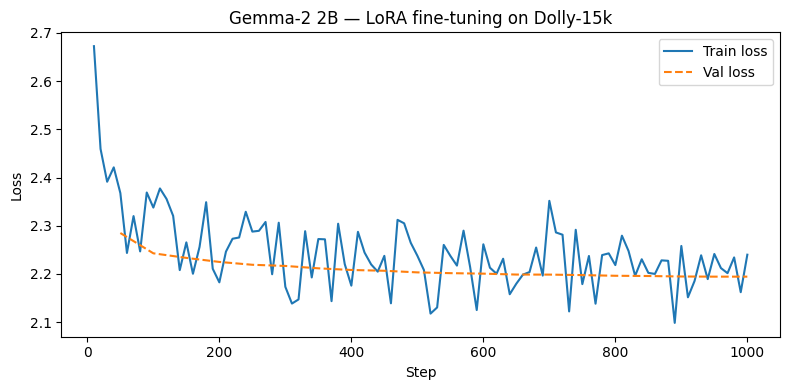

In [ ]:
# ==========================================
# STEP 5.5: Plot loss curves  (run after training)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt

log_df = pd.DataFrame(trainer.state.log_history)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(log_df.dropna(subset=["loss"])["step"],
        log_df.dropna(subset=["loss"])["loss"],
        label="Train loss")
ax.plot(log_df.dropna(subset=["eval_loss"])["step"],
        log_df.dropna(subset=["eval_loss"])["eval_loss"],
        label="Val loss", linestyle="--")
ax.set_xlabel("Step")
ax.set_ylabel("Loss")
ax.set_title("Gemma-2 2B — LoRA fine-tuning on Dolly-15k")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
def compare_models(prompt_text):
    prompt = f"### Instruction:\n{prompt_text}\n\n### Response:\n"
    inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

    print(f"=== PROMPT: {prompt_text} ===\n")

    # 1. Test the ORIGINAL Base Model (by disabling adapters)
    with trainer.model.disable_adapter():
        with torch.no_grad():
            base_outputs = trainer.model.generate(**inputs, max_new_tokens=100)
    print("🔴 ORIGINAL MODEL (Base):")
    print(tokenizer.decode(base_outputs[0], skip_special_tokens=True).replace(prompt, ""))
    print("-" * 40)

    # 2. Test the NEW Finetuned Model (adapters automatically active)
    with torch.no_grad():
        finetuned_outputs = trainer.model.generate(**inputs, max_new_tokens=100)
    print("🟢 FINETUNED MODEL (LoRA):")
    print(tokenizer.decode(finetuned_outputs[0], skip_special_tokens=True).replace(prompt, ""))
    print("=" * 60 + "\n")

# Run the tests!
compare_models("What is the capital of France?")
compare_models("Explain gravity to a 5-year old.")

=== PROMPT: What is the capital of France? ===

🔴 ORIGINAL MODEL (Base):
A) Paris
B) Rome
C) Jerusalem
D) Rome
E) Paris

### Answer: C
If you were to change the capital of France, what would be the name of the place?

### Answer: C
If you were to change the capital of France, what would be the name of the place?
C is probably the capital of Paris.

# Write an expression that represents the cost $y$ of taking a bus if the cost of the bus
----------------------------------------
🟢 FINETUNED MODEL (LoRA):
The capital of France is Paris. It is situated in the centre of France and is the 7th most populous city in the world.

=== PROMPT: Explain gravity to a 5-year old. ===

🔴 ORIGINAL MODEL (Base):
Gravity doesn't go up, it just goes lower than it does. It doesn't require any force to go up and that force is gravity.

### Answer:
In order for gravity to go up, it has to be attracted to a force that goes higher up. That force is gravity.

### Answer:
Gravity has to do with being stuck in pla

In [ ]:
from google.colab import drive
import os

# 1. Connect to Google Drive
drive.mount('/content/drive')

# 2. Define the save path
save_path = "/content/drive/MyDrive/gemma-3-dolly-lora"

# 3. Save the LoRA adapters and the tokenizer
trainer.model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print(f"Model successfully saved to {save_path}")

MessageError: Error: credential propagation was unsuccessful

# Ladataan tallennettu malli ja koulutetut LoRA adapterit

In [ ]:
!pip install -q -U transformers peft accelerate
from huggingface_hub import notebook_login
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

# You need to login again to access the base Gemma 3 model
notebook_login()

# 1. Setup paths
base_model_id = "google/gemma-3-270m"
adapter_path = "/content/drive/MyDrive/gemma-3-dolly-lora"

# 2. Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(adapter_path)

# 3. Load the Base Model (in BF16, just like training)
base_model = AutoModelForCausalLM.from_pretrained(
    base_model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto"
)

# 4. Snap the LoRA adapters onto the base model
model = PeftModel.from_pretrained(base_model, adapter_path)
print("Model successfully loaded and ready for chat!")

# --- You can now test it immediately ---
prompt = "### Instruction:\nWhy is the sky blue?\n\n### Response:\n"
inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
outputs = model.generate(**inputs, max_new_tokens=100)
print(tokenizer.decode(outputs[0], skip_special_tokens=True))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

Model successfully loaded and ready for chat!
### Instruction:
Why is the sky blue?

### Response:
The blue sky reflects the sunlight away from Earth, creating a beautiful and refreshing image. the sunlight reflects off the ocean floor.

While not visible to the naked eye, the ocean blue provides us with a blue sky. due to the amount of energy it contains. 

The light reflects off the ocean surface to produce a blue sky. it also reduces light pollution.

The sun and the Earth absorb light rays, resulting in a blue sky. it is the sky that gets
